# V2 inference by input filename
Run setup, then inference. Set INPUT_FILES to input filenames in paths.csv.
INPUT_FILES=None processes all CSV entries. Input stroke annotation columns are ignored.


In [1]:
from pathlib import Path
import sys, subprocess, tempfile
root = Path(tempfile.mkdtemp(prefix="reference_v2_", dir="/content"))
subprocess.run(["git", "clone", "--depth", "1", "--branch", "main",
                "https://github.com/yechan25/hsqm.git", str(root)], check=True)
if not (root / "requirements.txt").is_file():
    raise FileNotFoundError("저장소에서 requirements.txt를 찾지 못했습니다.")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(root / "requirements.txt")], check=True)
sys.path.insert(0, str(root))
for key in list(sys.modules):
    if key == "stroke_model" or key.startswith("stroke_model."):
        del sys.modules[key]
commit = subprocess.check_output(["git", "-C", str(root), "rev-parse", "--short", "HEAD"], text=True).strip()
print("모델 코드 준비 완료 / GitHub 버전:", commit)


모델 코드 준비 완료 / GitHub 버전: 7f4da09


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoint: /content/drive/Shareddrives/2026 자율연구/HSQM/stroke_zip_runs/20261028_082616_066020/best.pt
CSV: /content/drive/Shareddrives/2026 자율연구/HSQM/dataset/test_dataset/path.csv
Inference: 1 samples, cuda. Input stroke annotations are not used.


/tmp/ipykernel_492/2604502860.py:118: UserWarning: Glyph 4354 (\N{HANGUL CHOSEONG NIEUN}) missing from font(s) DejaVu Sans.
  figure.tight_layout()
/tmp/ipykernel_492/2604502860.py:118: UserWarning: Glyph 4462 (\N{HANGUL JUNGSEONG U}) missing from font(s) DejaVu Sans.
  figure.tight_layout()
/tmp/ipykernel_492/2604502860.py:118: UserWarning: Glyph 4535 (\N{HANGUL JONGSEONG MIEUM}) missing from font(s) DejaVu Sans.
  figure.tight_layout()
/tmp/ipykernel_492/2604502860.py:119: UserWarning: Glyph 4354 (\N{HANGUL CHOSEONG NIEUN}) missing from font(s) DejaVu Sans.
  figure.savefig(str(prefix) + '.png', dpi=140)
/tmp/ipykernel_492/2604502860.py:119: UserWarning: Glyph 4462 (\N{HANGUL JUNGSEONG U}) missing from font(s) DejaVu Sans.
  figure.savefig(str(prefix) + '.png', dpi=140)
/tmp/ipykernel_492/2604502860.py:119: UserWarning: Glyph 4535 (\N{HANGUL JONGSEONG MIEUM}) missing from font(s) DejaVu Sans.
  figure.savefig(str(prefix) + '.png', dpi=140)
/usr/local/lib/python3.13/dist-packages/IPyt

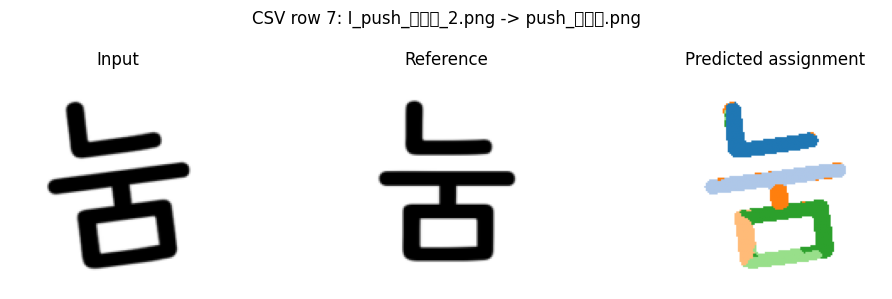

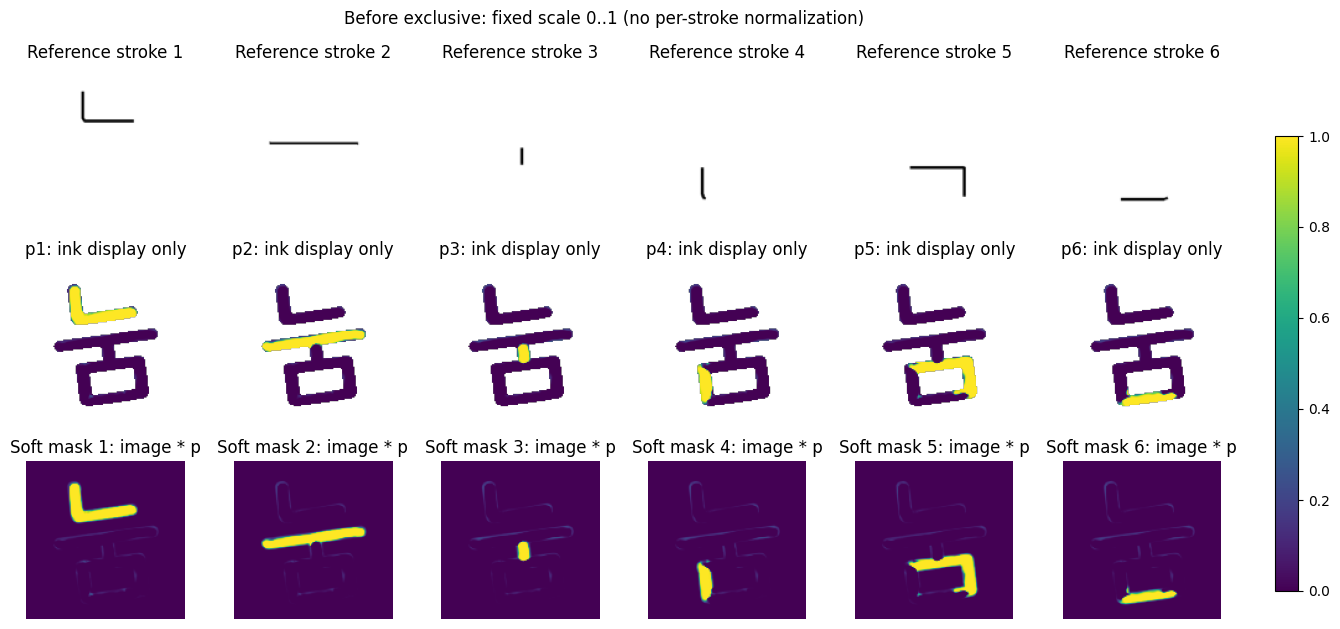

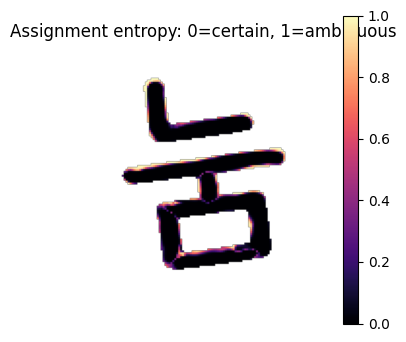

Saved: /content/drive/Shareddrives/2026 자율연구/HSQM/stroke_zip_runs/20261028_082616_066020/inference_20261111_110220_188949


In [4]:
"""V2 inference from CSV without input-stroke annotations or label conversion."""
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from stroke_model.convert_reference_csv import Resolver, existing_path, load_ink, path_list, normalized
from stroke_model.reference_model import ReferenceStrokeModel
from stroke_model.preview_reference import show_soft_strokes


def inference_columns(frame):
    names = {str(c).lower(): c for c in frame.columns}
    def find(*aliases):
        for name in aliases:
            if name.lower() in names:
                return names[name.lower()]
        raise ValueError(f'Missing CSV column: {aliases}; found {list(frame.columns)}')
    return {
        'image': find('I_prep', 'input_image_path', 'input_path', 'input_image', 'input', 'source_path'),
        'reference': find('I_g', 'reference_image', 'reference_path', 'target_image', 'target_path', 'glyph_path'),
        'strokes': find('I_G_strokes', 'reference_strokes', 'reference_stroke_paths', 'template_strokes', 'target_strokes', 'target_stroke_paths'),
    }


def load_inference_row(row, columns, resolve, size):
    # Deliberately never access input_stroke_paths or total_paths.
    image_path = resolve(row[columns['image']])
    reference_path = resolve(row[columns['reference']])
    paths = path_list(row[columns['strokes']])
    if not paths:
        raise ValueError('Reference stroke list is empty')
    image = torch.from_numpy(load_ink(image_path, size))
    reference = torch.from_numpy(load_ink(reference_path, size))
    strokes = torch.from_numpy(np.concatenate([load_ink(resolve(p), size) for p in paths]))
    if not (strokes.flatten(1).max(1).values > .5).all():
        raise ValueError('Empty reference stroke image')
    return image, reference, strokes, image_path, reference_path


def select_input_files(frame, image_column, input_files):
    if isinstance(input_files, str):
        input_files = [input_files]
    values = [normalized(str(value).strip()) for value in frame[image_column]]
    selected = []
    for requested in input_files:
        name = normalized(str(requested).strip())
        # A bare filename matches a basename; a path matches the CSV path exactly.
        matches = [i + 1 for i, value in enumerate(values)
                   if (value == name if '/' in name else value.rsplit('/', 1)[-1] == name)]
        if not matches:
            raise ValueError(f'Input filename not found in CSV: {requested}')
        if len(matches) != 1:
            raise ValueError(f'Ambiguous input filename: {requested}; CSV rows {matches}. Specify the CSV input path or sample_rows.')
        if matches[0] not in selected:
            selected.append(matches[0])
    return selected


def run_inference_csv(checkpoint, csv_path, sample_rows=None, dataset_root=None,
                      input_files=None,
                      save_dir=None, show_soft=True):
    """sample_rows: one-based CSV data row numbers; None processes all rows.

    Outputs are stroke assignments, not calibrated missing/extra-stroke decisions.
    No annotation metrics are computed. Existing checkpoints remain unchanged.
    """
    import matplotlib.pyplot as plt
    import json

    checkpoint, csv_path = existing_path(checkpoint), existing_path(csv_path)
    frame = pd.read_csv(csv_path)
    columns = inference_columns(frame)
    if input_files is not None and sample_rows is not None:
        raise ValueError('Specify input_files or sample_rows, not both')
    selected = (select_input_files(frame, columns['image'], input_files) if input_files is not None
                else list(range(1, len(frame) + 1)) if sample_rows is None else list(sample_rows))
    if not selected or any(not isinstance(n, int) or not 1 <= n <= len(frame) for n in selected):
        raise ValueError(f'sample_rows must contain data row numbers in 1..{len(frame)}')
    resolve = Resolver(csv_path, existing_path(dataset_root) if dataset_root else csv_path.parent)
    state = torch.load(checkpoint, map_location='cpu', weights_only=True)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = ReferenceStrokeModel(image_size=state['image_size'], width=state['width'], pretrained=False)
    model.load_state_dict(state['model'], strict=True)
    model = model.to(device).eval()
    size = state['image_size']
    del state
    destination = Path(save_dir) if save_dir else checkpoint.parent / ('inference_' + datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
    destination.mkdir(parents=True, exist_ok=False)
    results = []
    print(f'Inference: {len(selected)} samples, {device}. Input stroke annotations are not used.')
    for number in selected:
        try:
            image, reference, strokes, image_path, reference_path = load_inference_row(
                frame.iloc[number - 1], columns, resolve, size)
            with torch.inference_mode():
                output = model(image[None].to(device), reference[None].to(device), strokes[None].to(device))
            probabilities = output['probabilities'][0].float().cpu().numpy()
            masks = output['masks'][0].float().cpu().numpy()
            prediction = probabilities.argmax(0)
            ink = image[0].numpy() > .5
            labels = np.where(ink, prediction, -1)
            prefix = destination / f'row_{number:04d}'
            np.savez_compressed(str(prefix) + '.npz', probabilities=probabilities,
                                soft_masks=masks, labels=labels, image=image.numpy(),
                                reference=reference.numpy(), reference_strokes=strokes.numpy())
            palette = plt.get_cmap('tab20')(np.arange(len(strokes)) % 20)[:, :3]
            colored = np.ones((*prediction.shape, 3))
            colored[ink] = palette[prediction[ink]]
            figure, axes = plt.subplots(1, 3, figsize=(10, 3))
            for ax, (content, title) in zip(axes, [(image[0], 'Input'), (reference[0], 'Reference'), (colored, 'Predicted assignment')]):
                ax.imshow(content, cmap='gray_r', vmin=0, vmax=1)
                ax.set_title(title)
                ax.axis('off')
            figure.suptitle(f'CSV row {number}: {image_path.name} -> {reference_path.name}')
            figure.tight_layout()
            figure.savefig(str(prefix) + '.png', dpi=140)
            plt.show()
            plt.close(figure)
            if show_soft:
                show_soft_strokes(image, strokes, output, prefix=prefix)
            results.append({'csv_row': number, 'input': str(image_path), 'reference': str(reference_path),
                            'npz': str(prefix) + '.npz', 'preview': str(prefix) + '.png'})
        except (ValueError, FileNotFoundError) as exc:
            raise ValueError(f'CSV data row {number}: {exc}') from exc
    report = {'checkpoint': str(checkpoint), 'csv': str(csv_path), 'uses_input_stroke_annotations': False,
              'results': results}
    (destination / 'inference.json').write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8')
    print('Saved:', destination)
    return report

# Run after the existing setup cell and Drive mount. No new GitHub code is required.
from google.colab import drive
drive.mount("/content/drive")
HSQM = existing_path("/content/drive/Shareddrives/2026 자율연구/HSQM")
# Reuse checkpoint/test_csv from the previous cell when available.
CHECKPOINT = globals().get("checkpoint")
if CHECKPOINT is None:
    candidates = sorted((HSQM / "stroke_zip_runs").glob("*/best.pt"))
    if not candidates:
        raise FileNotFoundError("Set CHECKPOINT to your V2 best.pt path")
    CHECKPOINT = candidates[-1]
CSV_PATH = globals().get("test_csv", HSQM / "dataset/test_dataset/path.csv")
DATASET_ROOT = None  # Set a parent image folder if images are not under the CSV folder.
INPUT_FILES = ["I_push_눔_2.png"]  # Input filenames in CSV. None = all files.
SHOW_SOFT = True
print("Checkpoint:", CHECKPOINT)
print("CSV:", CSV_PATH)
inference_results = run_inference_csv(
    CHECKPOINT, CSV_PATH, input_files=INPUT_FILES,
    dataset_root=DATASET_ROOT, show_soft=SHOW_SOFT,
)
